In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neural_network import MLPClassifier
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# load in the wine data
wine = load_wine()

data = pd.DataFrame(wine.data, columns = wine.feature_names)
data

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [3]:
# Feature matrix in a object named X
X = wine.data
# response vector in a object named y
y = wine.target # gives 3 classes of wine cultivars 

print(np.shape(X))
print(np.shape(y))

(178, 13)
(178,)


In [4]:
# Split wine data in train and test data (80:20)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=4)

In [5]:
# scale the training data
scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# now build the neural network using MLPClassifier
# MLPClassifier stands for Multi-layer Perceptron classifier

# the following code will create a classifier with three layers of 10 nodes each
# max_iter refers to the number of epochs, one epoch is a combination of one cycle of 
# feed-forward and back propagation phase.
mlp = MLPClassifier(hidden_layer_sizes=(10, 10, 10), max_iter=1000, random_state=4)

# now fit the classifer to the training data
mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",4
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [10]:
# try making some predictions using your classifier
predictions = mlp.predict(X_test)

In [8]:
# and now look at the accuracy of your predictions
print(confusion_matrix(y_test,predictions)) # Confusion Matrix

# We will use the confusion matrix to determine the accuracy which is measured as the total 
# number of correct predictions divided by the total number of predictions.

[[10  0  0]
 [ 0 13  0]
 [ 0  0 13]]


row 0: 10 samples total, 10 predicted correctly as class 0; row 1: 13 samples total, 13 predicted correctly as class 1; row 2: 13 samples total, 13 predicted correctly as class 2

0s in the other positions means the model made 0 classification errors on the test set 

In [11]:
# look at the accuracy of your predictions
print(classification_report(y_test,predictions)) # Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



this baseline model got 100% accuracy score (1.00)

In [14]:
import warnings
warnings.filterwarnings('ignore')

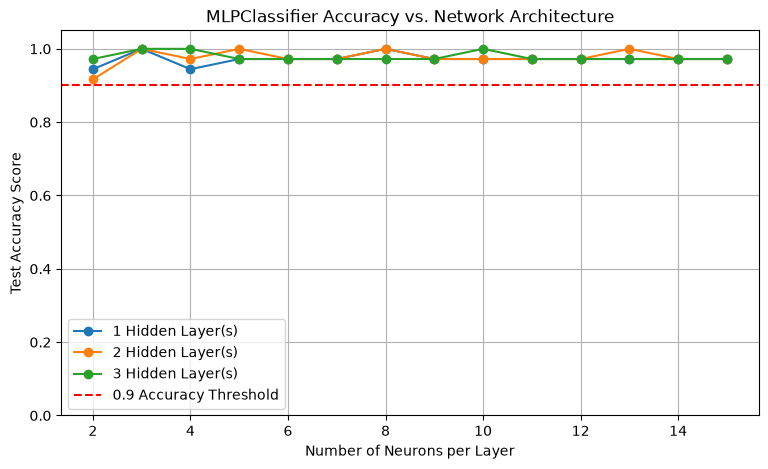

In [17]:
layer_counts = [1, 2, 3]             # Testing 1, 2, and 3 hidden layers
neuron_counts = range(2, 16, 1)      # Testing 2 to 15 neurons per layer

results = []

# loop over each combination of hidden layers and neurons
for num_layers in layer_counts:
    for n_neurons in neuron_counts:
        # Construct the hidden_layer_sizes tuple (e.g., 2 layers with 5 neurons = (5, 5))
        architecture = tuple([n_neurons] * num_layers)
        
        # build and train the MLPClassifier
        mlp = MLPClassifier(hidden_layer_sizes=architecture, max_iter=1000, random_state=4)
        mlp.fit(X_train, y_train)
        
        # predict and evaluate accuracy
        y_pred = mlp.predict(X_test)
        acc = metrics.accuracy_score(y_test, y_pred)
        
        # save results for analysis
        results.append({
            'num_layers': num_layers,
            'neurons_per_layer': n_neurons,
            'architecture': str(architecture),
            'accuracy': acc,
            'model': mlp,
            'y_pred': y_pred
        })

results_df = pd.DataFrame(results)

plt.figure(figsize=(9, 5))

for num_layers in layer_counts:
    subset = results_df[results_df['num_layers'] == num_layers]
    plt.plot(subset['neurons_per_layer'], subset['accuracy'], marker='o', label=f'{num_layers} Hidden Layer(s)')

plt.axhline(y=0.9, color='r', linestyle='--', label='0.9 Accuracy Threshold')
plt.title('MLPClassifier Accuracy vs. Network Architecture')
plt.xlabel('Number of Neurons per Layer')
plt.ylabel('Test Accuracy Score')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

All combinations of hidden layers and neuron counts (2-15 neurons per layer) yielded a test accuracy score above 0.9, impling that even a small architecture has sufficient capacity to separate wine classes when trained on scaled features. A configuation of three neurons per layer produced a test accuracy score of 1.0 across all hidden layer counts. Thus, I choose to use the simpilest model that produces a test score of 1.0, which would be one hidden layer with 3 neurons. Selecting a smaller network would likely speed up training and reduce risk of overfitting. 

Since all 42 architecture combinations yielded test accuracy scores greater than 0.9, I will first create a loop to analyze all accuracy scores for all combinations. I will then select a representative set of architectures spanning minimal, medium and deep networks to evaluate the confusion matrices, precision, recall, and F1 scores for each target class. 

In [22]:
summary_data = []

for res in results:
    if res['accuracy'] > 0.9:
        # Calculate confusion matrix & detailed report
        cm = confusion_matrix(y_test, res['y_pred'])
        report = classification_report(y_test, res['y_pred'], target_names=wine.target_names, output_dict=True)
        
        # Store key metrics for each target class
        summary_data.append({
            'Architecture': res['architecture'],
            'Accuracy': f"{res['accuracy']:.4f}",
            'Class 0 F1': f"{report['class_0']['f1-score']:.2f}",
            'Class 1 F1': f"{report['class_1']['f1-score']:.2f}",
            'Class 2 F1': f"{report['class_2']['f1-score']:.2f}"
        })

# Display as a clean DataFrame summary showing ALL rows
summary_df = pd.DataFrame(summary_data)
print(f"Total combinations evaluated with accuracy > 0.9: {len(summary_df)}")

# Display every single architecture without cutoff
pd.set_option('display.max_rows', None)
display(summary_df)

Total combinations evaluated with accuracy > 0.9: 42


,Architecture,Accuracy,Class 0 F1,Class 1 F1,Class 2 F1
0,"(2,)",0.9444,0.95,0.92,0.96
1,"(3,)",1.0000,1.00,1.00,1.00
2,"(4,)",0.9444,0.95,0.92,0.96
3,"(5,)",0.9722,1.00,0.96,0.96
4,"(6,)",0.9722,1.00,0.96,0.96
5,"(7,)",0.9722,1.00,0.96,0.96
6,"(8,)",1.0000,1.00,1.00,1.00
7,"(9,)",0.9722,1.00,0.96,0.96
8,"(10,)",0.9722,1.00,0.96,0.96
9,"(11,)",0.9722,1.00,0.96,0.96


In [24]:
representative_architectures = [
    (3,),          # (1 hidden layer, 3 neurons)
    (7, 7),        # (2 hidden layers, 5 neurons each)
    (15, 15, 15)   # (3 hidden layers, 15 neurons each)
]

for arch in representative_architectures:
    print("=" * 65)
    print(f"ARCHITECTURE: {arch} | Hidden Layers: {len(arch)} | Neurons per Layer: {arch[0]}")
    print("=" * 65)
    
    # Train the MLPClassifier for this architecture
    mlp_rep = MLPClassifier(hidden_layer_sizes=arch, max_iter=1000, random_state=4)
    mlp_rep.fit(X_train, y_train)
    
    # Make predictions on test set
    y_pred_rep = mlp_rep.predict(X_test)
    
    # 1. Confusion Matrix
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred_rep))
    print("-" * 65)
    
    # 2. Precision, Recall, and F1-Score Report
    print("Classification Report:")
    print(classification_report(y_test, y_pred_rep, target_names=wine.target_names))
    print("\n")

ARCHITECTURE: (3,) | Hidden Layers: 1 | Neurons per Layer: 3
Confusion Matrix:
[[10  0  0]
 [ 0 13  0]
 [ 0  0 13]]
-----------------------------------------------------------------
Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        10
     class_1       1.00      1.00      1.00        13
     class_2       1.00      1.00      1.00        13

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



ARCHITECTURE: (7, 7) | Hidden Layers: 2 | Neurons per Layer: 7
Confusion Matrix:
[[10  0  0]
 [ 0 13  0]
 [ 0  1 12]]
-----------------------------------------------------------------
Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        10
     class_1       0.93      1.00      0.96        13
     class_2       1.00      0.92      0.9

Across the selected medium and deep networks, the model performed great for class 0, consistently producing precision, recall, and f1 scores of 1.0, but struggled for class 1 and 2, producing slightly lower precision, recall, and f1 scores. Based on the confusion matrices, it appears that the model can confuse class 1 and class 2. This implies that the chemical features of class 0 are completely distinct, whereas there may be some overlap in features between class 1 and 2 that causes misclassification errors. 

Since an architecture of one layer with 3 neurons accurately classifies classes with 100% certainty (precision=1.0), identifies every actual instance of each individual class without missing or overlooking any of them (recall=1.0), and produces an error free confusion matrix (features in wine dataset are distinct enough), I will use this architecture for the final version of my model. 

In [31]:
# load the unknown wine dataset
unknown_wine = pd.read_csv('unknown_wine.csv')
unknown_wine

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.20,1.75,2.44,15.3,115.3,3.17,3.35,0.33,2.05,6.52,1.04,3.09,1363.0,0
1,13.46,3.45,2.17,18.4,89.8,2.47,2.67,0.27,1.54,4.50,0.95,2.99,1089.5,0
2,13.74,1.79,2.57,15.6,111.8,3.34,3.33,0.31,1.65,7.16,1.15,3.06,1243.6,0
3,14.24,3.68,2.43,17.9,109.5,2.91,2.82,0.30,1.54,5.54,0.92,3.28,1152.1,0
4,13.82,1.63,2.26,16.9,98.6,2.43,2.59,0.27,1.69,5.00,1.09,2.97,1179.1,0
5,13.49,1.78,2.57,20.1,100.6,2.63,2.67,0.27,1.84,4.15,1.09,3.67,909.8,0
6,13.06,1.78,2.32,15.5,99.8,2.69,3.12,0.24,2.68,6.26,1.11,2.98,1070.6,0
7,13.52,3.20,2.58,15.6,114.1,2.65,2.93,0.18,1.71,5.05,0.97,3.39,833.4,0
8,14.08,1.74,2.34,16.2,109.7,3.05,2.93,0.27,1.96,6.15,1.00,3.20,1063.9,0
9,13.56,3.21,2.34,19.0,95.0,2.61,2.74,0.31,1.56,4.40,1.01,3.13,993.3,0


In [30]:
unknown_wine.shape

(178, 14)

In [33]:
print(unknown_wine.columns.tolist())

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']


In [35]:
# drop the target column because that variable wasn't in our first dataset 
X_unknown = unknown_wine.drop(columns=['target'])
X_unknown_scaled = scaler.transform(X_unknown)
X_unknown_scaled.shape

(178, 13)

In [36]:
final_mlp = MLPClassifier(hidden_layer_sizes=(3,), max_iter=1000, random_state=4)
final_mlp.fit(X_train, y_train)

# predict discrete target classes for unknown wines
unknown_preds = final_mlp.predict(X_unknown_scaled)

# calculate prediction probabilities for all 3 classes
unknown_probs = final_mlp.predict_proba(X_unknown_scaled)

# format and display results in a neat summary table
results_list = []
for i, (pred, probs) in enumerate(zip(unknown_preds, unknown_probs)):
    results_list.append({
        'Sample': f"Unknown {i+1}",
        'Predicted Class': f"Class {pred} ({wine.target_names[pred]})",
        'Class 0 Prob': f"{probs[0]:.4f}",
        'Class 1 Prob': f"{probs[1]:.4f}",
        'Class 2 Prob': f"{probs[2]:.4f}",
        'Model Confidence': f"{probs[pred]*100:.2f}%"
    })

results_df = pd.DataFrame(results_list)
display(results_df)

,Sample,Predicted Class,Class 0 Prob,Class 1 Prob,Class 2 Prob,Model Confidence
0,Unknown 1,Class 0 (class_0),0.9981,0.0001,0.0018,99.81%
1,Unknown 2,Class 0 (class_0),0.9478,0.0247,0.0275,94.78%
2,Unknown 3,Class 0 (class_0),0.9966,0.0003,0.0031,99.66%
3,Unknown 4,Class 0 (class_0),0.9964,0.0003,0.0032,99.64%
4,Unknown 5,Class 0 (class_0),0.9790,0.0066,0.0144,97.90%
5,Unknown 6,Class 0 (class_0),0.9220,0.0425,0.0355,92.20%
6,Unknown 7,Class 0 (class_0),0.9430,0.0279,0.0291,94.30%
7,Unknown 8,Class 0 (class_0),0.9832,0.0047,0.0122,98.32%
8,Unknown 9,Class 0 (class_0),0.9926,0.0012,0.0062,99.26%
9,Unknown 10,Class 0 (class_0),0.9595,0.0174,0.0232,95.95%


I used the scikit-learn function predict_proba() to obtain outputs where each sample/ row contains 3 numbers that equal to 1. 

Unknown samples 1-59 were classified as class 0, unknown samples 60-130 belong to class 1, and unknown samples 131-178 fell under class 2. 4 samples classified as class 0 received a confidence score less than 0.9, with the lowest being 0.79, 8 samples classified as class 1 received a score less than 0.9, with the lowest being 0.73, and 2 samples classified as class 2 received a score less than 0.9 but greater than 0.85. Only 2 samples in class one received a perfect score of 100%, but considering majority of the samples (164/178) obtained a confidence score above 0.9, I would argue that the model performed well and is pretty decisive about its predictions. 